In [210]:
import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
from sboxes.loader import load as load_sbox
from evaluation.uniformity import ddt
from evaluation.avalanche_criterion import print_avalanche_summary, plot_avalanche_matrix
from evaluation.markov_chains.basic_markov_chain import DifferentialMarkovChain

from evaluation.markov_chains.basic_markov_chain import create_transition_matrix, create_transition_matrix_from_sbox

In [211]:
def test_sbox_markov(sbox, epsilon=1e-4, r_values=[1,2,5,10]):
    """
    Ejecuta pruebas de Markov en la S-Box:
     - Doble estocasticidad, irreducibilidad, aperiodicidad, ergodicidad
     - Mixing times iterativo y espectral
     - TV distance y max probability
     - Gráfica TV distance vs pasos
    """
    print(f"\n### Pruebas MarkovChain para {type(sbox).__name__}")
    P = create_transition_matrix_from_sbox(sbox)
    chain = DifferentialMarkovChain(P)

    # Propiedades
    print("Doble estocástica:", chain.is_doubly_stochastic())
    print("Irreducible:", chain.is_irreducible())
    print("Aperiodic:", chain.is_aperiodic())
    print("Ergódica:", chain.is_ergodic())

    # Mixing times
    tau_iter = chain.mixing_time_iterative(epsilon)
    tau_spec = chain.mixing_time_spectral(epsilon)
    print(f"Mixing time iterativo (ε={epsilon}): {tau_iter}")
    print(f"Mixing time espectral  (ε={epsilon}): {tau_spec}")

    # TV distance y max probability
    for r in r_values:
        tv = chain.tv_distance(r)
        mp = chain.max_probability(r)
        print(f"Paso {r}: TV_distance={tv:.6f}, max_probability={mp:.6f}")

    # Gráfica TV distance vs r
    rs = list(range(1, max(r_values)+1))
    tvs = [chain.tv_distance(r) for r in rs]
    plt.figure(figsize=(6,4))
    plt.plot(rs, tvs, marker='o')
    plt.title(f"TV Distance vs Steps: {type(sbox).__name__}")
    plt.xlabel("Steps r")
    plt.ylabel("TV Distance")
    plt.grid(True)
    plt.show()

In [212]:
# Cargar ASCON S-Box
ascon = load_sbox('sboxes/data/ascon.json')
print('# S-Box ASCON')

# S-Box ASCON


## 1. Avalanche Criterion
SAC promedio general: 0.620
Desviación estándar máxima: 0.374
╒═════╤═══════════╤═══════════╕
│     │   Avg SAC │   Std SAC │
╞═════╪═══════════╪═══════════╡
│ In0 │       0.6 │     0.2   │
├─────┼───────────┼───────────┤
│ In1 │       0.7 │     0.245 │
├─────┼───────────┼───────────┤
│ In2 │       0.6 │     0.374 │
├─────┼───────────┼───────────┤
│ In3 │       0.7 │     0.245 │
├─────┼───────────┼───────────┤
│ In4 │       0.5 │     0.316 │
╘═════╧═══════════╧═══════════╛


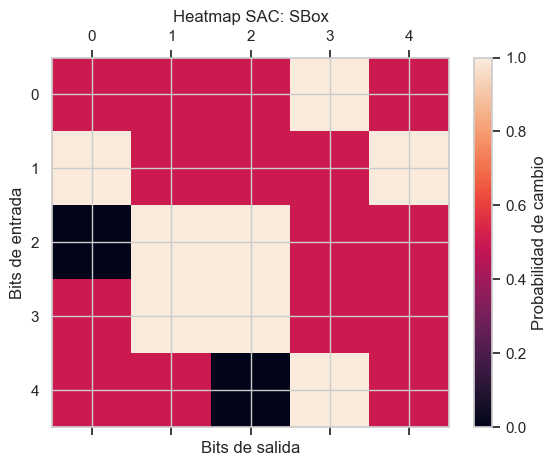

In [213]:
# 1. Avalanche Criterion
print('## 1. Avalanche Criterion')
print_avalanche_summary(ascon)
plot_avalanche_matrix(ascon)

## 2. Pruebas de la Cadena de Markov

### Pruebas MarkovChain para SBox
Doble estocástica: True
Irreducible: True


Aperiodic: True
Ergódica: True
Mixing time iterativo (ε=0.0001): 11
Mixing time espectral  (ε=0.0001): 14
Paso 1: TV_distance=0.870968, max_probability=0.250000
Paso 2: TV_distance=0.429435, max_probability=0.109375
Paso 5: TV_distance=0.018941, max_probability=0.035126
Paso 10: TV_distance=0.000116, max_probability=0.032278


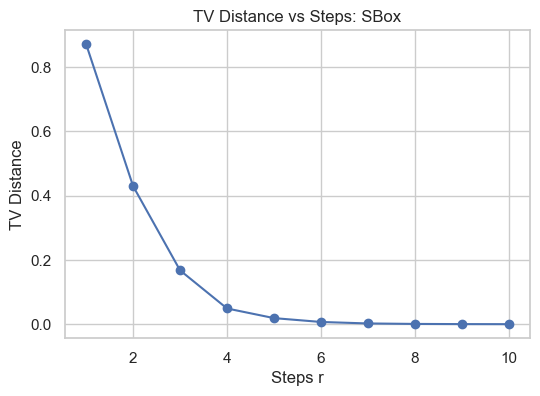

In [214]:
# 2. Pruebas de Cadena de Markov
print('## 2. Pruebas de la Cadena de Markov')
test_sbox_markov(ascon)

# Measures

In [215]:

from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox
from evaluation.markov_chains.all_test_markov_chains import (
    compare_tv_distance,
    compare_max_probability,
    compare_mixing_times
)
TABLEAU10 = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
TABLEAU10 = ["#e41a1c","#377eb8","#4daf4a","#984ea3","#ff7f00","#ffff33","#a65628","#f781bf","#999999"]

import seaborn as sns

COLORS_FOR_OWNS = sns.color_palette("ch:s=.25,rot=-.25", n_colors=10) [::-1]
#sns.palplot(sns.color_palette("Reds", n_colors=10))[::-3]  # Colores para las S-Boxes propias
COLORS_FOR_CLASICS = sns.color_palette("Reds", n_colors=10)[::-3]


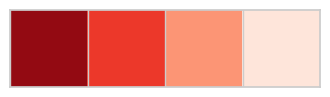

In [216]:
sns.palplot(sns.color_palette("Reds", n_colors=10)[::-3] )

In [217]:
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.fixed_points import fixed_ponts
from evaluation.uniformity import get_ddt
from evaluation.linearity import evaluate
from sboxes.loader import load as load_sbox

to_proof = ["ascon", "fides_5_AB", "APN5"]#"nuestro 5.v1", "nuestro 5.v2", "nuestro 5.v3"]
identidad = IdentitySBox(5)
#nuestra5_nuevo = load_sbox("sboxes/data/nuestro 5.2.json")
specs1 = []


for sbox_link in to_proof:
    sbox = load_sbox(f"sboxes/data/{sbox_link}.json")
    ddt = get_ddt(sbox)
    max_ddt = np.max(ddt[1:])        # ignoramos dx = 0
    uniformity = max_ddt
    fixed = fixed_ponts(sbox, detail=True)[1]
    non_linearities = evaluate(sbox)
    specs1.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': COLORS_FOR_CLASICS[len(specs1) % len(COLORS_FOR_CLASICS)],
        'sbox': sbox
        
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

0 -> 4
1 -> 11
2 -> 31
3 -> 20
4 -> 26
5 -> 21
6 -> 9
7 -> 2
8 -> 27
9 -> 5
10 -> 8
11 -> 18
12 -> 29
13 -> 3
14 -> 6
15 -> 28
16 -> 30
17 -> 19
18 -> 7
19 -> 14
20 -> 0
21 -> 13
22 -> 17
23 -> 24
24 -> 16
25 -> 12
26 -> 1
27 -> 25
28 -> 22
29 -> 10
30 -> 15
31 -> 23
Procesando S-Box: ASCON (5x5)
0 -> 1
1 -> 0
2 -> 25
3 -> 26
4 -> 17
5 -> 29
6 -> 21
7 -> 27
8 -> 20
9 -> 5
10 -> 4
11 -> 23
12 -> 14
13 -> 18
14 -> 2
15 -> 28
16 -> 15
17 -> 8
18 -> 6
19 -> 3
20 -> 13
21 -> 7
22 -> 24
23 -> 16
24 -> 30
25 -> 9
26 -> 31
27 -> 10
28 -> 22
29 -> 12
30 -> 11
31 -> 19
Procesando S-Box: FIDES_5 (5x5)
0 -> 17
1 -> 21
2 -> 2
3 -> 22
4 -> 26
5 -> 20
6 -> 15
7 -> 9
8 -> 4
9 -> 1
10 -> 12
11 -> 0
12 -> 5
13 -> 7
14 -> 29
15 -> 27
16 -> 31
17 -> 24
18 -> 16
19 -> 19
20 -> 13
21 -> 18
22 -> 3
23 -> 11
24 -> 6
25 -> 30
26 -> 23
27 -> 10
28 -> 28
29 -> 14
30 -> 25
31 -> 8
Procesando S-Box: APN 5 (5x5)


In [218]:
import json
from sboxes import SBox

specs2 = []
# ---------- 1. Cargar el JSON ----------
with open("resultados/5x5/data.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# ---------- 2. Procesar cada S-Box ----------
for idx, sb in enumerate(data["sboxes"]):
 
    print(sb)        
    table = list(map(lambda x: hex(x), sb["table"]))                   # lista de enteros
    n_in  = int(np.log2(len(table)))            # nº de bits de entrada
    n_out = int(np.ceil(np.log2(max(sb["table"])+1)))  # nº de bits de salida
    name = f"Variant #{idx}"
    biggest_possible_output = 1 << n_out
    final_table = np.empty(len(table), dtype=np.uint64)
    for idx, i in enumerate(table):#sb["table"]):
        output = int(i, 0)
        if output > biggest_possible_output or output < 0:
            raise ValueError("Table values must be greater than or equal to 0 and less than or equal to 2^%d" % n_out)
        final_table[idx] = output
        
    sbox = SBox(n_in, n_out, final_table, name)                      # <- ajusta a tu clase
    print("size:",len(sb["table"]))
    specs2.append({
        "name": name,              # pon aquí el nombre que prefieras
        "table": sbox.table.tolist(),
        "n_in": n_in,
        "n_out": n_out,
        "color": COLORS_FOR_OWNS[len(specs2) % len(COLORS_FOR_OWNS)],
        "sbox":  sbox
    })

# ---------- 3. (Opcional) comprobar ----------
print(f"{len(specs2)} S-Boxes cargadas desde data.json")
for s in specs2:
    print(s["name"], "–", s["n_in"], "→", s["n_out"])

{'cost': 0.34749987228825485, 'linearity': 10.0, 'uniformity': 4.0, 'table': [17, 26, 13, 9, 25, 12, 24, 22, 5, 21, 8, 7, 30, 28, 29, 27, 0, 3, 14, 19, 15, 4, 23, 11, 10, 18, 2, 16, 6, 20, 31, 1]}
size: 32
{'cost': 0.348193030529809, 'linearity': 10.0, 'uniformity': 4.0, 'table': [25, 20, 12, 22, 10, 30, 21, 17, 7, 3, 0, 23, 1, 15, 5, 11, 26, 28, 27, 4, 31, 14, 13, 8, 19, 24, 2, 18, 16, 6, 9, 29]}
size: 32
{'cost': 0.348193030529809, 'linearity': 10.0, 'uniformity': 4.0, 'table': [3, 19, 10, 26, 29, 30, 22, 20, 14, 2, 5, 16, 8, 6, 0, 7, 31, 25, 13, 9, 18, 27, 21, 15, 4, 28, 12, 17, 11, 1, 23, 24]}
size: 32
{'cost': 0.34931754978728513, 'linearity': 10.0, 'uniformity': 4.0, 'table': [25, 19, 28, 29, 20, 11, 26, 18, 17, 4, 14, 31, 12, 16, 5, 1, 21, 23, 15, 3, 6, 13, 22, 24, 30, 27, 8, 9, 2, 7, 0, 10]}
size: 32
{'cost': 0.3501545845498617, 'linearity': 10.0, 'uniformity': 4.0, 'table': [12, 14, 20, 15, 16, 18, 22, 25, 10, 3, 24, 11, 1, 2, 0, 28, 13, 21, 30, 27, 9, 17, 29, 6, 19, 7, 23, 4,

In [219]:
specs = specs1 + specs2

In [220]:
for elem in specs:
    
    chain = DifferentialMarkovChain(create_transition_matrix_from_sbox(elem['sbox']))
    print(f"-- {elem['name']} --")
    print("Doble estocástica:", chain.is_doubly_stochastic())
    #print("Irreducible:", chain.is_irreducible())
    #print("Aperiodic:", chain.is_aperiodic())
    print("Ergódica:", chain.is_ergodic())
    print()

-- ASCON --
Doble estocástica: True
Ergódica: True

-- FIDES_5 --
Doble estocástica: True
Ergódica: True

-- APN 5 --
Doble estocástica: True
Ergódica: True

-- Variant #0 --
Doble estocástica: True
Ergódica: True

-- Variant #1 --
Doble estocástica: True
Ergódica: True

-- Variant #2 --
Doble estocástica: True
Ergódica: True

-- Variant #3 --
Doble estocástica: True
Ergódica: True

-- Variant #4 --
Doble estocástica: True
Ergódica: True

-- Variant #5 --
Doble estocástica: True
Ergódica: True

-- Variant #6 --
Doble estocástica: True
Ergódica: True

-- Variant #7 --
Doble estocástica: True
Ergódica: True

-- Variant #8 --
Doble estocástica: True
Ergódica: True



|   r |    ASCON |   FIDES_5 |    APN 5 |   Variant #0 |   Variant #1 |   Variant #2 |   Variant #3 |   Variant #4 |   Variant #5 |   Variant #6 |   Variant #7 |   Variant #8 |
|-----|----------|-----------|----------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|
|   1 | 0.870968 |  0.483871 | 0.580645 |     0.612903 |     0.612903 |     0.612903 |     0.612903 |     0.645161 |     0.612903 |     0.645161 |     0.580645 |     0.612903 |
|   2 | 0.429435 |  0.068044 | 0.115801 |     0.145035 |     0.142137 |     0.128402 |     0.135207 |     0.12752  |     0.137223 |     0.146043 |     0.116683 |     0.12941  |
|   3 | 0.167465 |  0.011435 | 0.031998 |     0.029068 |     0.036393 |     0.031478 |     0.028549 |     0.028549 |     0.030108 |     0.038283 |     0.026777 |     0.034589 |
|   4 | 0.048938 |  0.002276 | 0.005801 |     0.006347 |     0.007475 |     0.007204 |     0.006759 |     0.005922 

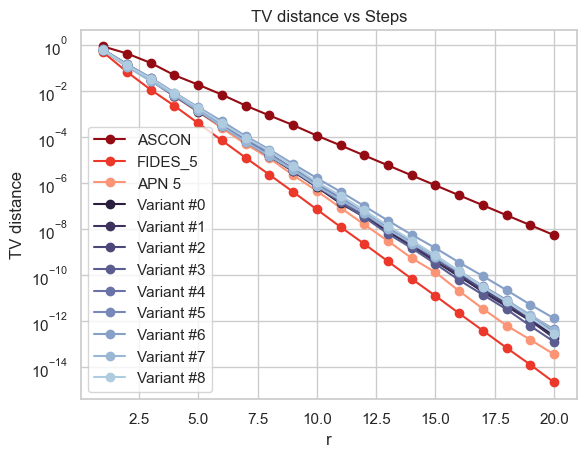

In [221]:
 # Comparaciones
ans = compare_tv_distance(specs, detail=True, graphic=True, log_scale=1)

|   r |    ASCON |   FIDES_5 |    APN 5 |   Variant #0 |   Variant #1 |   Variant #2 |   Variant #3 |   Variant #4 |   Variant #5 |   Variant #6 |   Variant #7 |   Variant #8 |
|-----|----------|-----------|----------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|--------------|
|   1 | 0.25     |  0.0625   | 0.125    |     0.125    |     0.125    |     0.125    |     0.125    |     0.125    |     0.1875   |     0.1875   |     0.125    |     0.125    |
|   2 | 0.109375 |  0.039062 | 0.0625   |     0.058594 |     0.058594 |     0.0625   |     0.054688 |     0.058594 |     0.058594 |     0.066406 |     0.0625   |     0.058594 |
|   3 | 0.056641 |  0.035156 | 0.036621 |     0.039307 |     0.037842 |     0.037354 |     0.038574 |     0.037109 |     0.038574 |     0.039062 |     0.038086 |     0.037109 |
|   4 | 0.041748 |  0.032715 | 0.033356 |     0.033615 |     0.033691 |     0.033401 |     0.03363  |     0.033432 

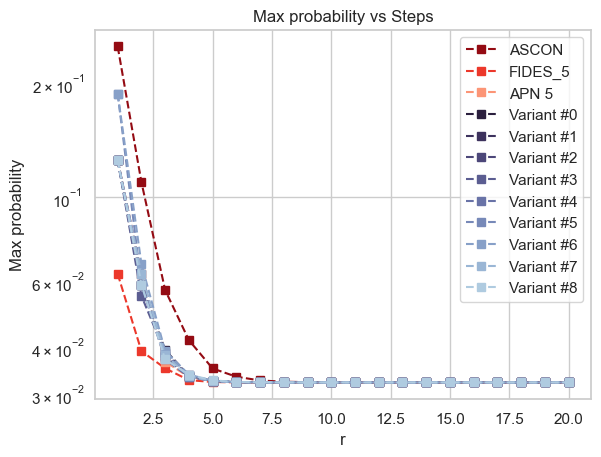

In [222]:
ans = compare_max_probability(specs, detail=True, graphic=True, log_scale=True)


|      ε |   ASCON iter |   FIDES_5 iter |   APN 5 iter |   Variant #0 iter |   Variant #1 iter |   Variant #2 iter |   Variant #3 iter |   Variant #4 iter |   Variant #5 iter |   Variant #6 iter |   Variant #7 iter |   Variant #8 iter |   ASCON spec |   FIDES_5 spec |   APN 5 spec |   Variant #0 spec |   Variant #1 spec |   Variant #2 spec |   Variant #3 spec |   Variant #4 spec |   Variant #5 spec |   Variant #6 spec |   Variant #7 spec |   Variant #8 spec |
|--------|--------------|----------------|--------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|--------------|----------------|--------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|-------------------|
| 0.1    |            4 |              2 |            3 |             

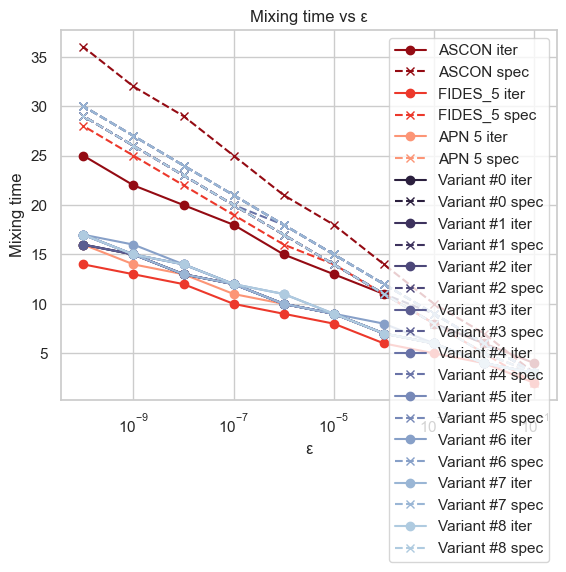

In [223]:
ans = compare_mixing_times(specs, detail=True, graphic=True, log_scale=True)    

## pruebas librerias

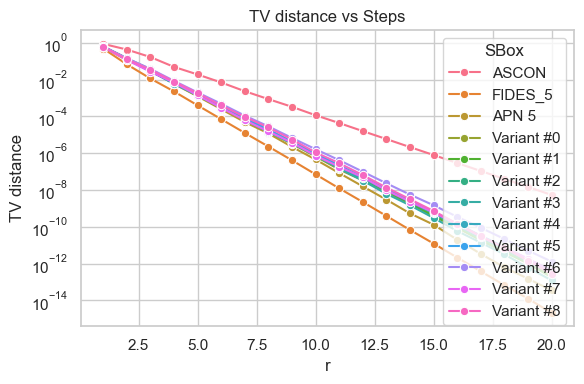

In [224]:
from evaluation.markov_chains.all_test_markov_chains import (
    compare_with_altair,
    compare_with_seaborn,
    compare_with_plotnine
)
compare_with_seaborn(specs, log_scale=1) 

In [225]:
compare_with_altair(specs, log_scale=1)  

c:\ProgramData\anaconda3\Lib\site-packages\altair\utils\core.py:395: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
c:\ProgramData\anaconda3\Lib\site-packages\altair\utils\core.py:395: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.


alt.Chart(...)

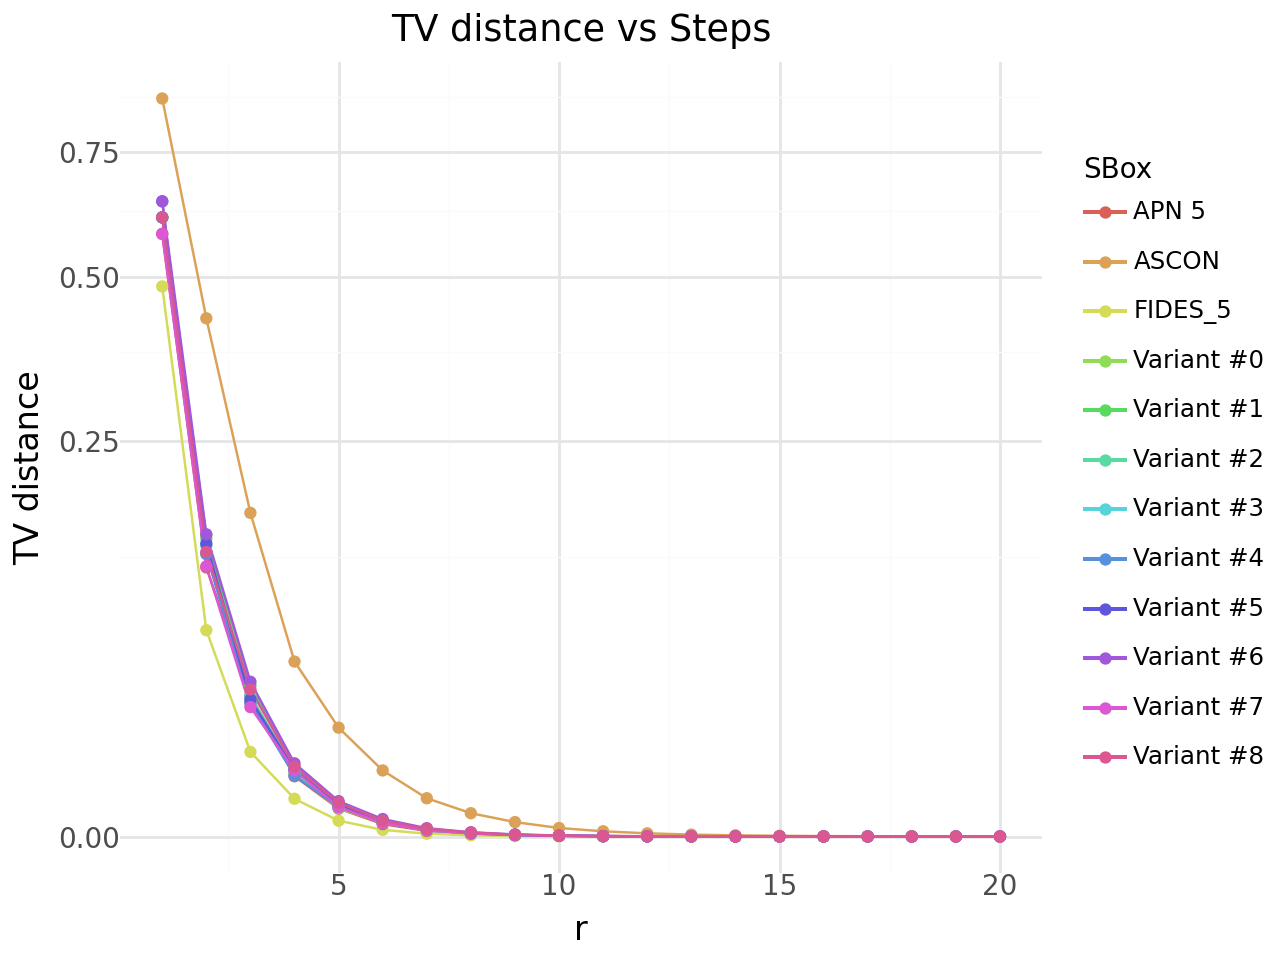

In [226]:
compare_with_plotnine(specs, log_scale=2) 

In [227]:
def compare_tv_distance(specs, detail: bool = False, graphic: bool = False, log_scale: bool = False, r_values=None, ):
    """
    Compara TV distance para varias S-Boxes.
    specs: lista de dicts {'name', 'table', 'n_in', 'n_out', 'color'}
    """
    if r_values is None:
        r_values = list(range(1, 21))
    # Crear cadenas
    chains = {
        spec['name']: (DifferentialMarkovChain(
                          create_transition_matrix(
                            np.array(spec['table']),
                            spec['n_in'], spec['n_out']
                          )),
                        spec['color'])
        for spec in specs
    }

    # Mostrar tabla
    headers = ['r'] + list(chains.keys())
    rows = []
    for r in r_values:
        row = [r] + [f"{chains[name][0].tv_distance(r):.6f}" for name in chains]
        rows.append(row)
    if detail:
        print(tabulate(rows, headers=headers, tablefmt="github"))

    # Graficar
    if graphic:
        plt.figure()
        for name, (chain, color) in chains.items():
            tvs = [chain.tv_distance(r) for r in r_values]
            plt.plot(r_values, tvs, 'o-', label=name, color=color)
        plt.xlabel('r')
        plt.ylabel('TV distance')
        if log_scale == 1:
            plt.yscale('log')
        elif log_scale == 2:
            plt.yscale('logit')
        plt.title('TV distance vs Steps')
        plt.legend()
        plt.grid(True)
        plt.show()
    return {name: [chain.tv_distance(r) for r in r_values] for name, (chain, _) in chains.items()}


# Clasicas

0 -> 4
1 -> 11
2 -> 31
3 -> 20
4 -> 26
5 -> 21
6 -> 9
7 -> 2
8 -> 27
9 -> 5
10 -> 8
11 -> 18
12 -> 29
13 -> 3
14 -> 6
15 -> 28
16 -> 30
17 -> 19
18 -> 7
19 -> 14
20 -> 0
21 -> 13
22 -> 17
23 -> 24
24 -> 16
25 -> 12
26 -> 1
27 -> 25
28 -> 22
29 -> 10
30 -> 15
31 -> 23
0 -> 1
1 -> 0
2 -> 25
3 -> 26
4 -> 17
5 -> 29
6 -> 21
7 -> 27
8 -> 20
9 -> 5
10 -> 4
11 -> 23
12 -> 14
13 -> 18
14 -> 2
15 -> 28
16 -> 15
17 -> 8
18 -> 6
19 -> 3
20 -> 13
21 -> 7
22 -> 24
23 -> 16
24 -> 30
25 -> 9
26 -> 31
27 -> 10
28 -> 22
29 -> 12
30 -> 11
31 -> 19
0 -> 17
1 -> 21
2 -> 2
3 -> 22
4 -> 26
5 -> 20
6 -> 15
7 -> 9
8 -> 4
9 -> 1
10 -> 12
11 -> 0
12 -> 5
13 -> 7
14 -> 29
15 -> 27
16 -> 31
17 -> 24
18 -> 16
19 -> 19
20 -> 13
21 -> 18
22 -> 3
23 -> 11
24 -> 6
25 -> 30
26 -> 23
27 -> 10
28 -> 28
29 -> 14
30 -> 25
31 -> 8
0 -> 17
1 -> 26
2 -> 13
3 -> 9
4 -> 25
5 -> 12
6 -> 24
7 -> 22
8 -> 5
9 -> 21
10 -> 8
11 -> 7
12 -> 30
13 -> 28
14 -> 29
15 -> 27
16 -> 0
17 -> 3
18 -> 14
19 -> 19
20 -> 15
21 -> 4
22 -> 23
23 -> 

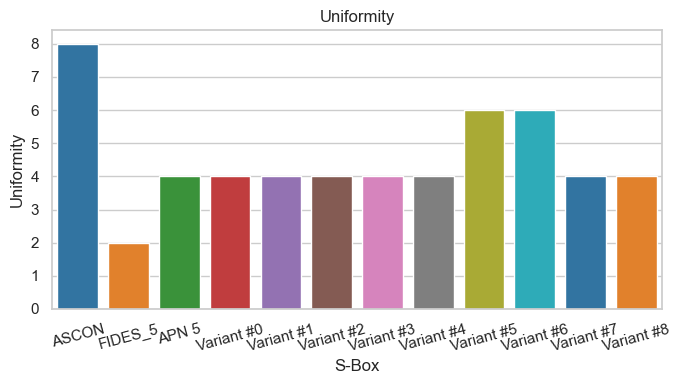

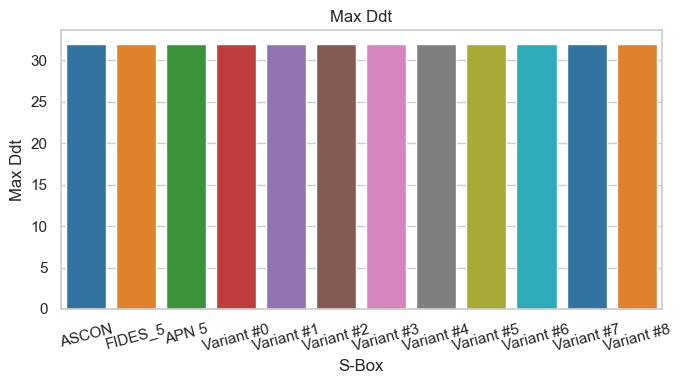

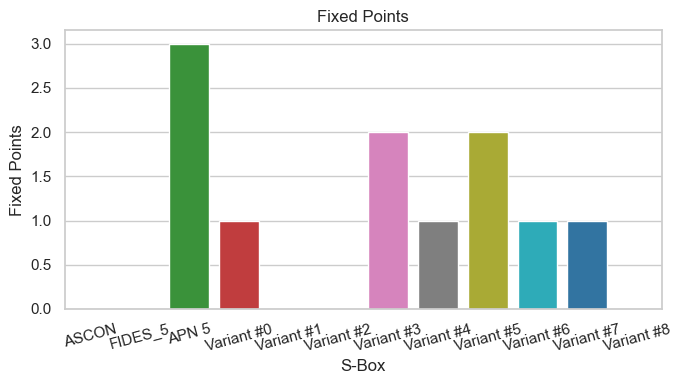

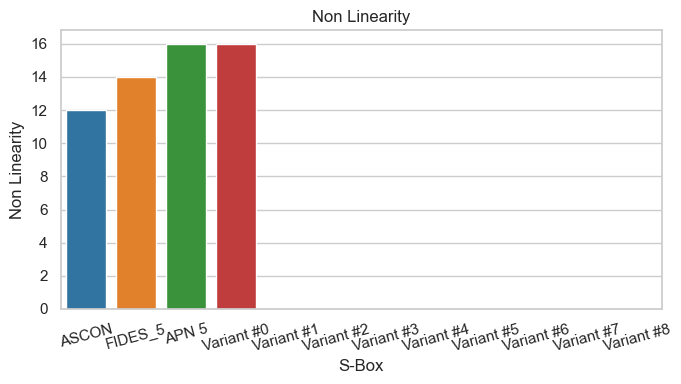

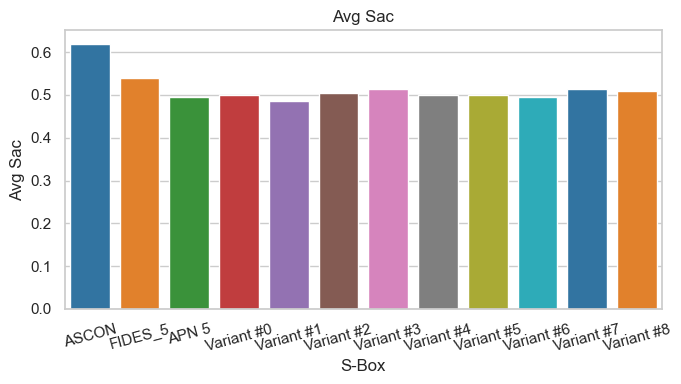

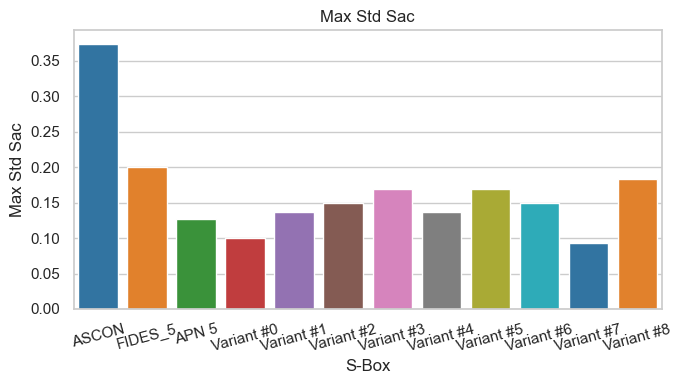

,name,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac
0,ASCON,8,32,0,12.0,0.620,0.374166
1,FIDES_5,2,32,0,14.0,0.540,0.200000
2,APN 5,4,32,3,16.0,0.495,0.127475
3,Variant #0,4,32,1,16.0,0.500,0.100000
4,Variant #1,4,32,0,NaN,0.485,0.136931
5,Variant #2,4,32,0,NaN,0.505,0.150000
6,Variant #3,4,32,2,NaN,0.515,0.169558
7,Variant #4,4,32,1,NaN,0.500,0.136931
8,Variant #5,6,32,2,NaN,0.500,0.169558
9,Variant #6,6,32,1,NaN,0.495,0.150000


In [228]:
from evaluation.sbox_metrics_analysis import run_all_metrics

# Define specs (como ya haces) y tus valores de no-linealidad:
non_linearities = [12, 14, 16, 16]  # valores que tú determines
run_all_metrics(specs, non_linearities)

In [229]:

from evaluation.markov_chains.basic_markov_chain import create_transition_matrix  # tu función
import numpy as np

import pandas as pd
from neurokit2 import markov_mixingtime

def compute_neurokit_mixing_time(sbox_table, n_in, n_out):
    P = create_transition_matrix(np.array(sbox_table), n_in, n_out)
    assert np.allclose(P.sum(axis=1), 1), "Matriz de transición inválida"

    # Crear índice y columnas etiquetadas para DataFrame
    states = [f"{i}" for i in range(P.shape[0])]
    tm = pd.DataFrame(P, index=states, columns=states)

    tau = markov_mixingtime(tm)
    return tau


for spec in specs:
    tau = compute_neurokit_mixing_time(spec['table'], spec['n_in'], spec['n_out'])
    print(f"{spec['name']}: Mixing time (NeuroKit) = {tau:.4f}")


ASCON: Mixing time (NeuroKit) = 1.5844
FIDES_5: Mixing time (NeuroKit) = 1.2147
APN 5: Mixing time (NeuroKit) = 1.2446
Variant #0: Mixing time (NeuroKit) = 1.2455
Variant #1: Mixing time (NeuroKit) = 1.2454
Variant #2: Mixing time (NeuroKit) = 1.2873
Variant #3: Mixing time (NeuroKit) = 1.1951
Variant #4: Mixing time (NeuroKit) = 1.1833
Variant #5: Mixing time (NeuroKit) = 1.2892
Variant #6: Mixing time (NeuroKit) = 1.2850
Variant #7: Mixing time (NeuroKit) = 1.2078
Variant #8: Mixing time (NeuroKit) = 1.2248
